In [1]:
!pip install -q ultralytics
from google.colab import drive
drive.mount('/content/drive')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 6.0 MB/s eta 0:00:00
Mounted at /content/drive


In [2]:
!ls /content/drive/MyDrive/week5

baseline_dataset.zip  week1_results.zip  week3_deliverables.zip


In [10]:
D = '/content/drive/MyDrive/week5'
!unzip -q "{D}/week1_results.zip" -d /
!unzip -q "{D}/week3_deliverables.zip" -d /
!unzip -q "{D}/baseline_dataset.zip" -d /content

replace /content/runs/baseline_yolov11n/val_batch1_pred.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
replace /content/week3_weights/Low_YOLOv26n_best.pt? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
replace /content/content/dataset_split/val/labels/srilankalorry196.txt? [y]es, [n]o, [A]ll, [N]one, [r]ename: A


In [12]:
!mv /content/content/dataset_split /content/dataset_split

In [13]:
!ls /content/dataset_split
!ls /content/dataset_split/test/images | wc -l
!ls /content/dataset_split/test/labels | wc -l

data.yaml  test  train	val
450
450


In [14]:
yaml = """path: /content/dataset_split
train: train/images
val: val/images
test: test/images
nc: 6
names: ['car', 'threewheel', 'bus', 'truck', 'motorbike', 'van']
"""
open('/content/dataset_split/data.yaml','w').write(yaml)

154

In [16]:
import os, glob, cv2, random, numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.image as mpimg
from ultralytics import YOLO

DATA = '/content/dataset_split/data.yaml'
CLASSES = ['car','threewheel','bus','truck','motorbike','van']
MODELS = ['YOLOv8n','YOLOv11n','YOLOv26n']
LEVELS = ['Baseline','Low','Medium','High']

BASE = {'YOLOv8n':'/content/runs/baseline_yolov8n-2',
        'YOLOv11n':'/content/runs/baseline_yolov11n',
        'YOLOv26n':'/content/runs/baseline_yolov26n'}

def folder(lvl, m):
    return BASE[m] if lvl=='Baseline' else f'/content/runs_week3/{lvl}_{m}'

weights = {(lvl,m): f'{folder(lvl,m)}/weights/best.pt' for lvl in LEVELS for m in MODELS}
print(len(weights), 'models')

12 models


In [17]:
r = YOLO(weights[('Low','YOLOv26n')]).val(data=DATA, split='test', verbose=False)
print(r.box.map50, r.box.map)   # expect about 0.9593 and 0.8694

Ultralytics 8.4.178 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO26n summary (fused): 120 layers, 2,376,006 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 568.2±408.9 MB/s, size: 91.8 KB)
val: Scanning /content/dataset_split/test/labels.cache... 450 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 450/450 75.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 29/29 2.5s/it 1:13
                   all        450        612      0.972       0.91      0.959      0.869
Speed: 5.9ms preprocess, 144.1ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to /content/runs/detect/val-5
0.9592905701326732 0.8693786099481696


Ultralytics 8.4.178 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 73 layers, 3,006,818 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1049.4±421.8 MB/s, size: 51.5 KB)
val: Scanning /content/dataset_split/test/labels.cache... 450 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 450/450 99.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 29/29 3.3s/it 1:36
                   all        450        612      0.928      0.886      0.933      0.834
Speed: 5.5ms preprocess, 196.0ms inference, 0.0ms loss, 0.5ms postprocess per image
Ultralytics 8.4.178 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,583,322 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2552.8±1005.3 MB/s, size: 163.7 KB)
val: Scanning /content/dataset_split/test/labels.cache... 45

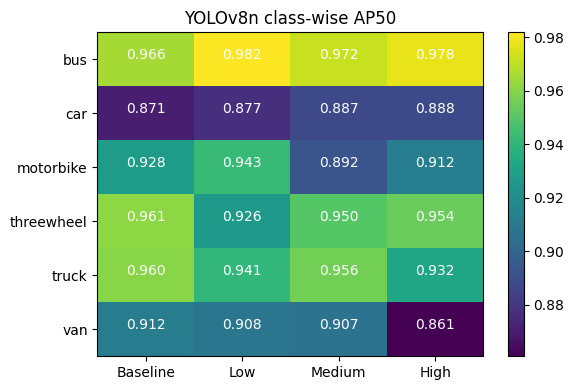

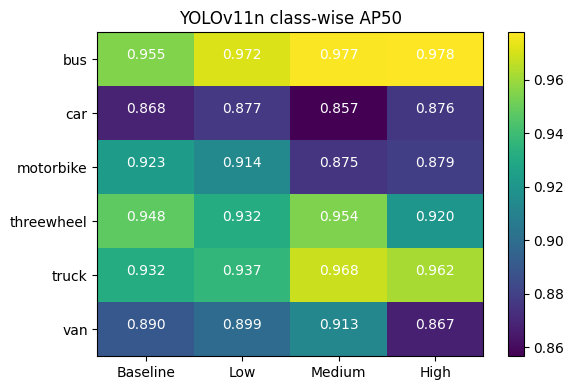

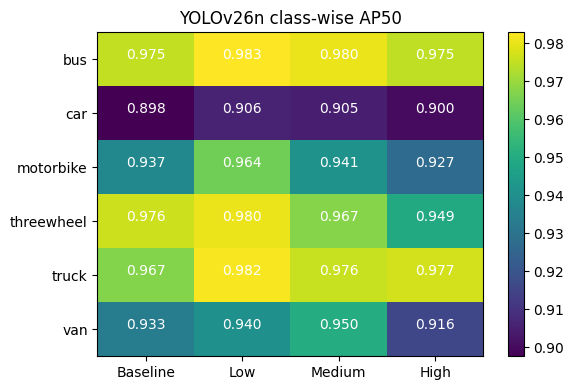

In [18]:
rows = []
for (lvl,m), w in weights.items():
    r = YOLO(w).val(data=DATA, split='test', verbose=False, plots=False)
    for i, c in enumerate(r.box.ap_class_index):
        rows.append(dict(Intensity=lvl, Model=m, Class=CLASSES[c],
                         AP50=r.box.ap50[i], AP50_95=r.box.ap[i]))
cls_df = pd.DataFrame(rows)
cls_df.to_csv('classwise_AP.csv', index=False)

# one heatmap per model: rows = class, columns = intensity
for m in MODELS:
    t = cls_df[cls_df.Model==m].pivot(index='Class', columns='Intensity', values='AP50')[LEVELS]
    plt.figure(figsize=(6,4)); plt.imshow(t.values, cmap='viridis', aspect='auto')
    plt.xticks(range(4), LEVELS); plt.yticks(range(6), t.index)
    for i in range(6):
        for j in range(4): plt.text(j, i, f'{t.values[i,j]:.3f}', ha='center', color='w')
    plt.title(f'{m} class-wise AP50'); plt.colorbar(); plt.tight_layout()
    plt.savefig(f'classwise_{m}.png', dpi=150); plt.show()

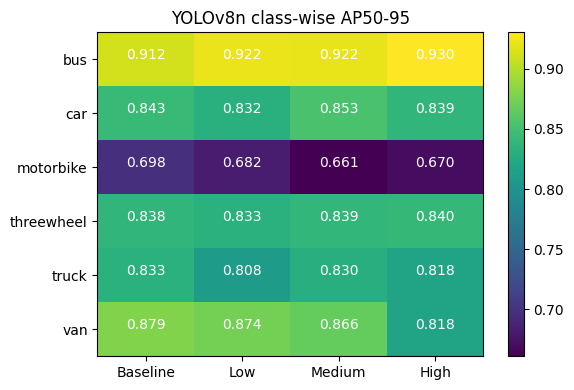

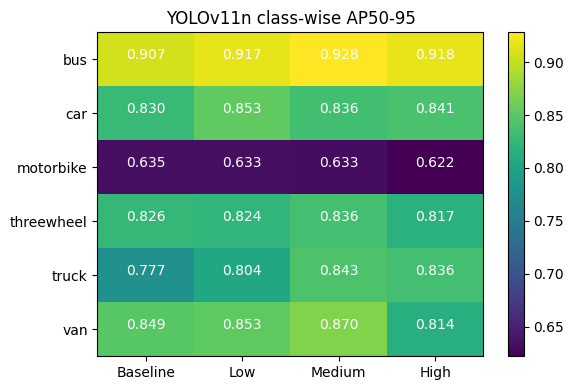

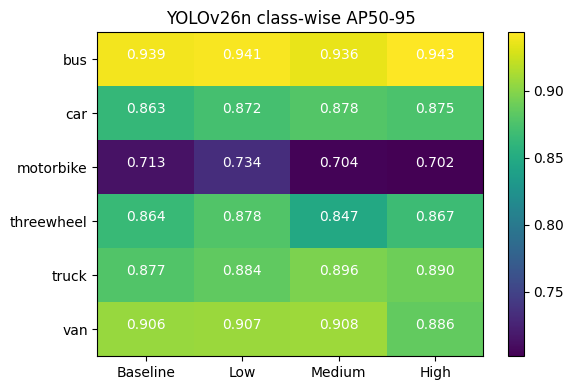

In [19]:
for metric, tag in [('AP50_95', 'AP50-95')]:
    for m in MODELS:
        t = cls_df[cls_df.Model==m].pivot(index='Class', columns='Intensity', values=metric)[LEVELS]
        plt.figure(figsize=(6,4)); plt.imshow(t.values, cmap='viridis', aspect='auto')
        plt.xticks(range(4), LEVELS); plt.yticks(range(6), t.index)
        for i in range(6):
            for j in range(4): plt.text(j, i, f'{t.values[i,j]:.3f}', ha='center', color='w')
        plt.title(f'{m} class-wise {tag}'); plt.colorbar(); plt.tight_layout()
        plt.savefig(f'classwise_{tag}_{m}.png', dpi=150); plt.show()

In [20]:
TEST_IMG = '/content/dataset_split/test/images'
TEST_LBL = '/content/dataset_split/test/labels'

def iou(a, b):
    x1,y1 = max(a[0],b[0]), max(a[1],b[1]); x2,y2 = min(a[2],b[2]), min(a[3],b[3])
    inter = max(0,x2-x1)*max(0,y2-y1)
    ua = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter/ua if ua > 0 else 0

def analyse(model, img_path, lbl_path, conf=0.25):
    h, w = cv2.imread(img_path).shape[:2]
    gts = []
    for l in open(lbl_path):
        c,xc,yc,bw,bh = l.split()[:5]; c=int(c); xc,yc,bw,bh = map(float,(xc,yc,bw,bh))
        gts.append(dict(cls=c, area=bw*bh, hit=False,
                        box=((xc-bw/2)*w,(yc-bh/2)*h,(xc+bw/2)*w,(yc+bh/2)*h)))
    res = model.predict(img_path, conf=conf, verbose=False)[0]
    preds = sorted(zip(res.boxes.cls.int().tolist(), res.boxes.xyxy.tolist(),
                       res.boxes.conf.tolist()), key=lambda x: -x[2])
    tp, fp = [], []
    for c, box, s in preds:
        best, bi = 0, None
        for i, g in enumerate(gts):
            if g['hit'] or g['cls'] != c: continue
            v = iou(box, g['box'])
            if v > best: best, bi = v, i
        if best >= 0.5: gts[bi]['hit'] = True; tp.append((box,c,s))
        else: fp.append((box,c,s))
    fn = [g for g in gts if not g['hit']]
    return gts, tp, fp, fn

In [21]:
imgs = sorted(glob.glob(TEST_IMG + '/*'))
lbl_of = lambda ip: f"{TEST_LBL}/{os.path.splitext(os.path.basename(ip))[0]}.txt"

areas = [float(l.split()[3])*float(l.split()[4]) for f in glob.glob(TEST_LBL+'/*.txt') for l in open(f)]
q1, q2 = np.percentile(areas, [33.3, 66.6])
bucket = lambda a: 'Small' if a < q1 else ('Medium' if a < q2 else 'Large')

rows = []
for (lvl,m), w in weights.items():
    model = YOLO(w)
    st = {'Small':[0,0], 'Medium':[0,0], 'Large':[0,0]}; TP=FP=FN=0
    for ip in imgs:
        gts, tp, fp, fn = analyse(model, ip, lbl_of(ip))
        TP+=len(tp); FP+=len(fp); FN+=len(fn)
        for g in gts:
            b = bucket(g['area']); st[b][1]+=1; st[b][0]+=g['hit']
    rows.append(dict(Intensity=lvl, Model=m, TP=TP, FP=FP, FN=FN,
                     **{f'Recall_{k}': v[0]/v[1] for k,v in st.items()}))
size_df = pd.DataFrame(rows); size_df.to_csv('size_stratified.csv', index=False)
size_df

,Intensity,Model,TP,FP,FN,Recall_Small,Recall_Medium,Recall_Large
0,Baseline,YOLOv8n,551,72,61,0.764706,0.975369,0.960976
1,Baseline,YOLOv11n,536,84,76,0.710784,0.965517,0.951220
2,Baseline,YOLOv26n,564,41,48,0.799020,0.975369,0.990244
3,Low,YOLOv8n,537,60,75,0.705882,0.960591,0.965854
4,Low,YOLOv11n,545,72,67,0.750000,0.955665,0.965854
5,Low,YOLOv26n,566,51,46,0.803922,0.990148,0.980488
6,Medium,YOLOv8n,541,64,71,0.740196,0.955665,0.956098
7,Medium,YOLOv11n,550,65,62,0.754902,0.960591,0.980488
8,Medium,YOLOv26n,561,56,51,0.794118,0.970443,0.985366
9,High,YOLOv8n,539,74,73,0.740196,0.955665,0.946341


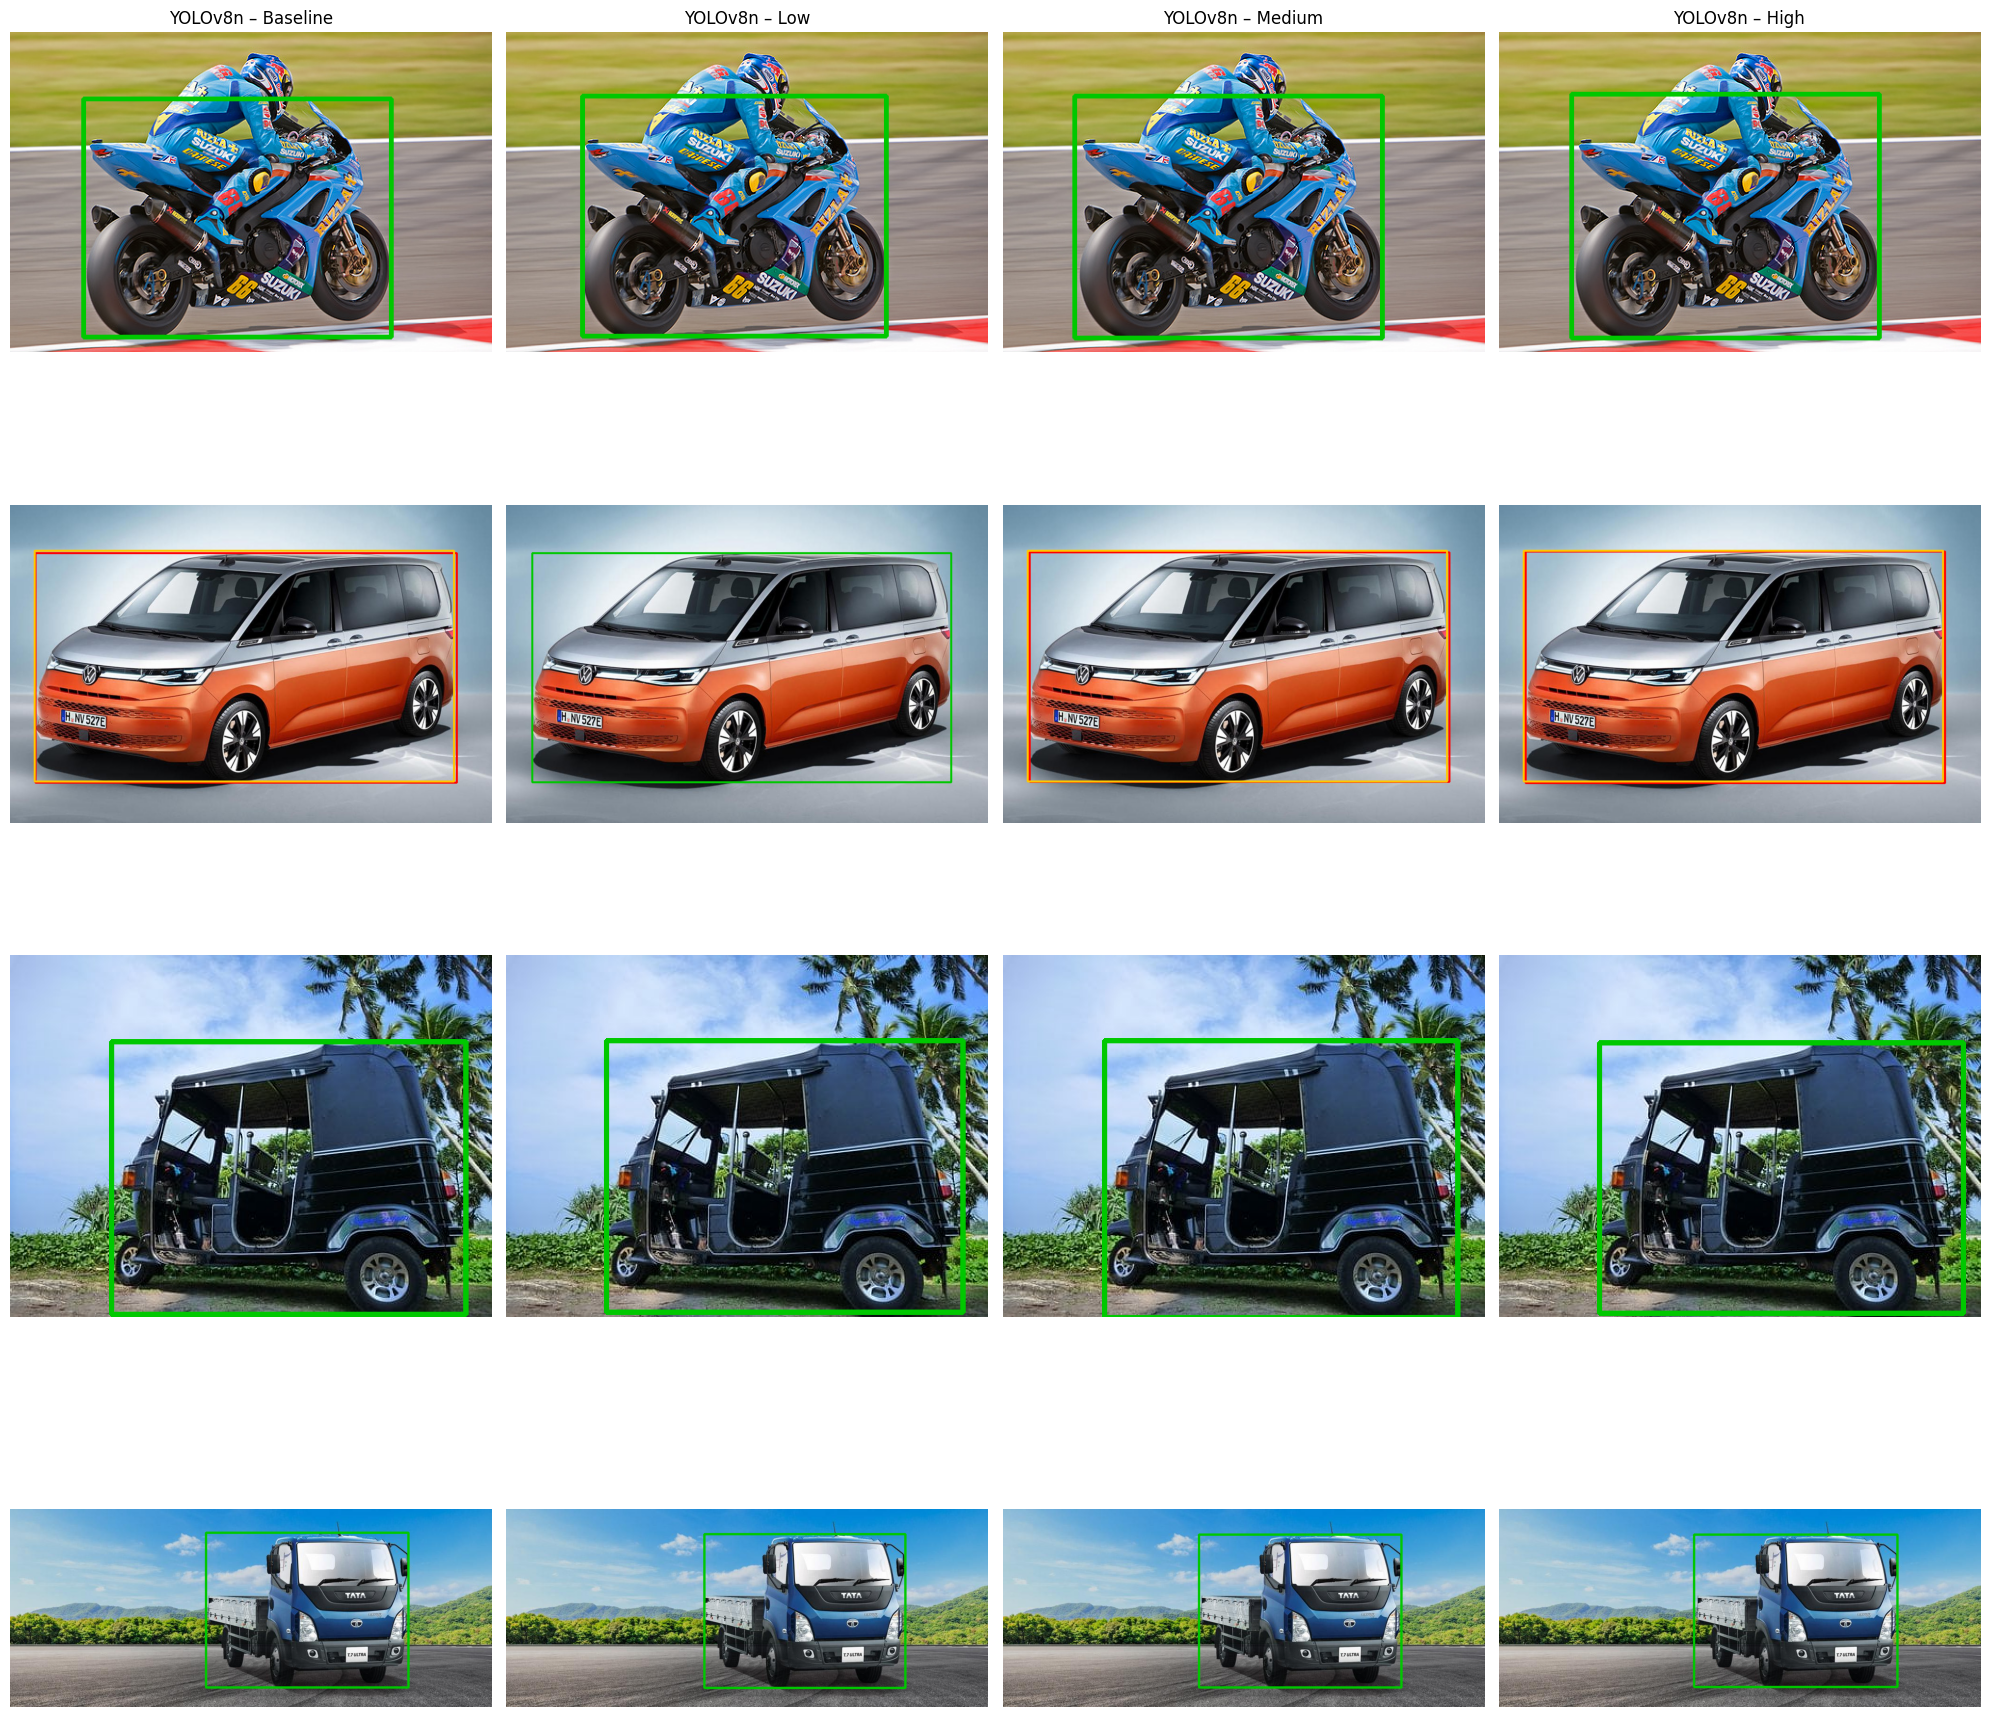

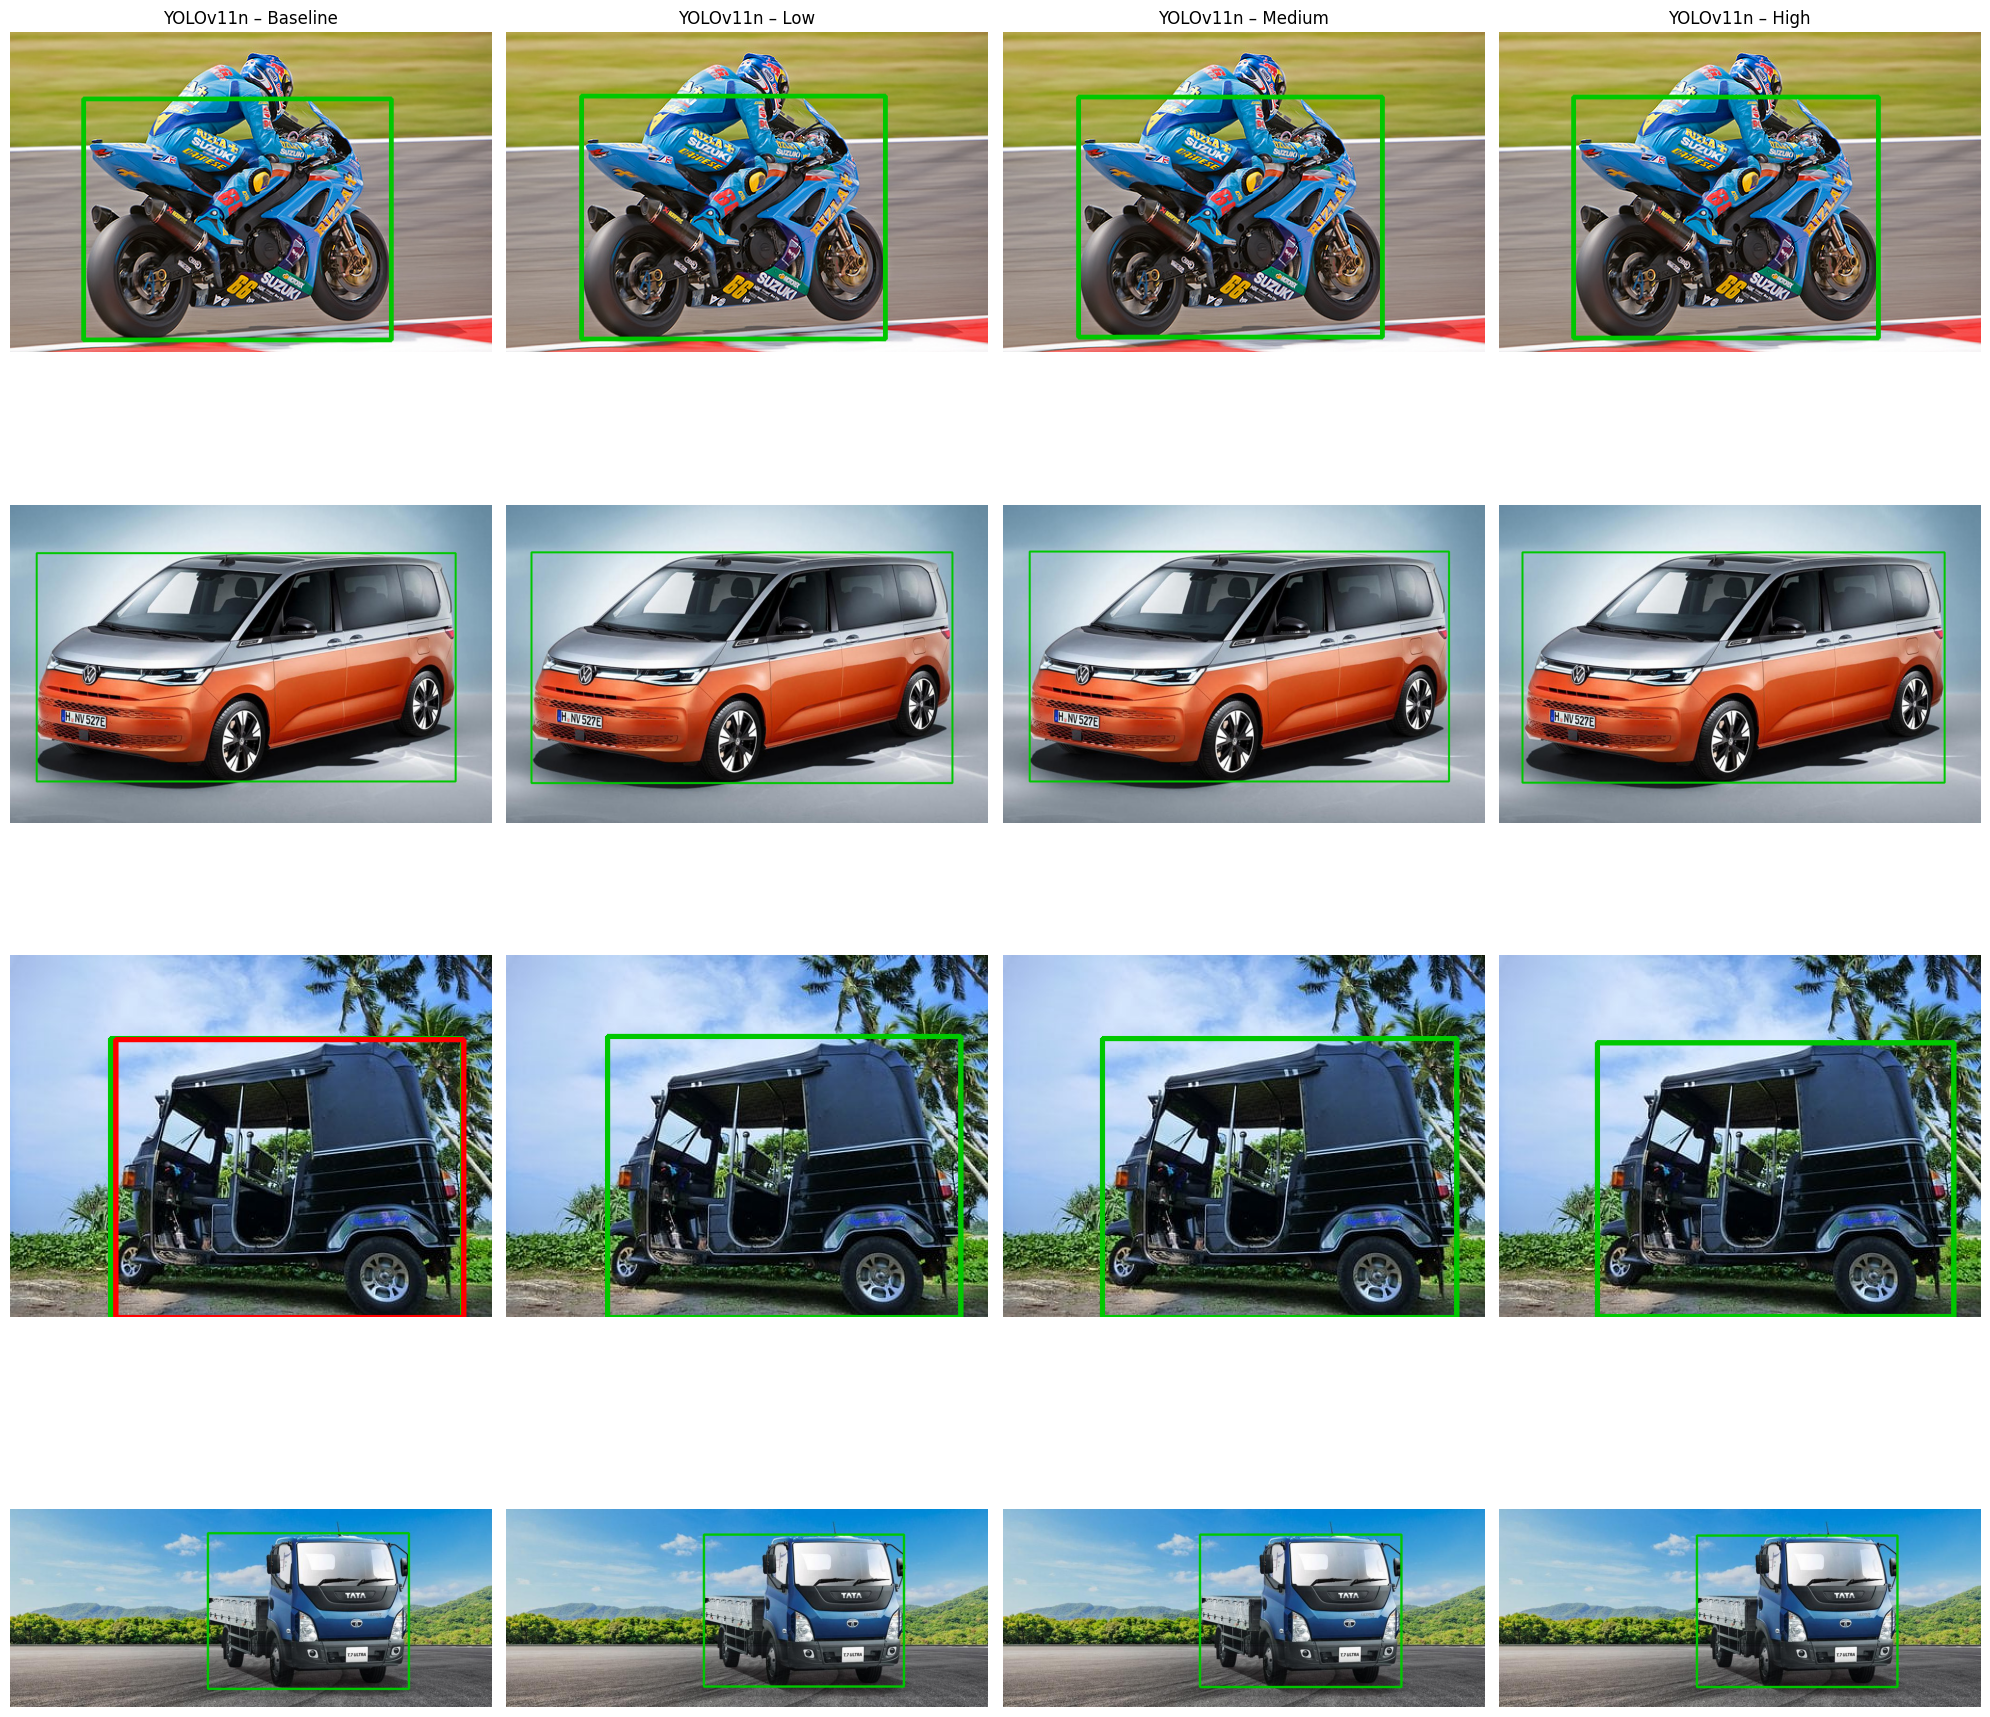

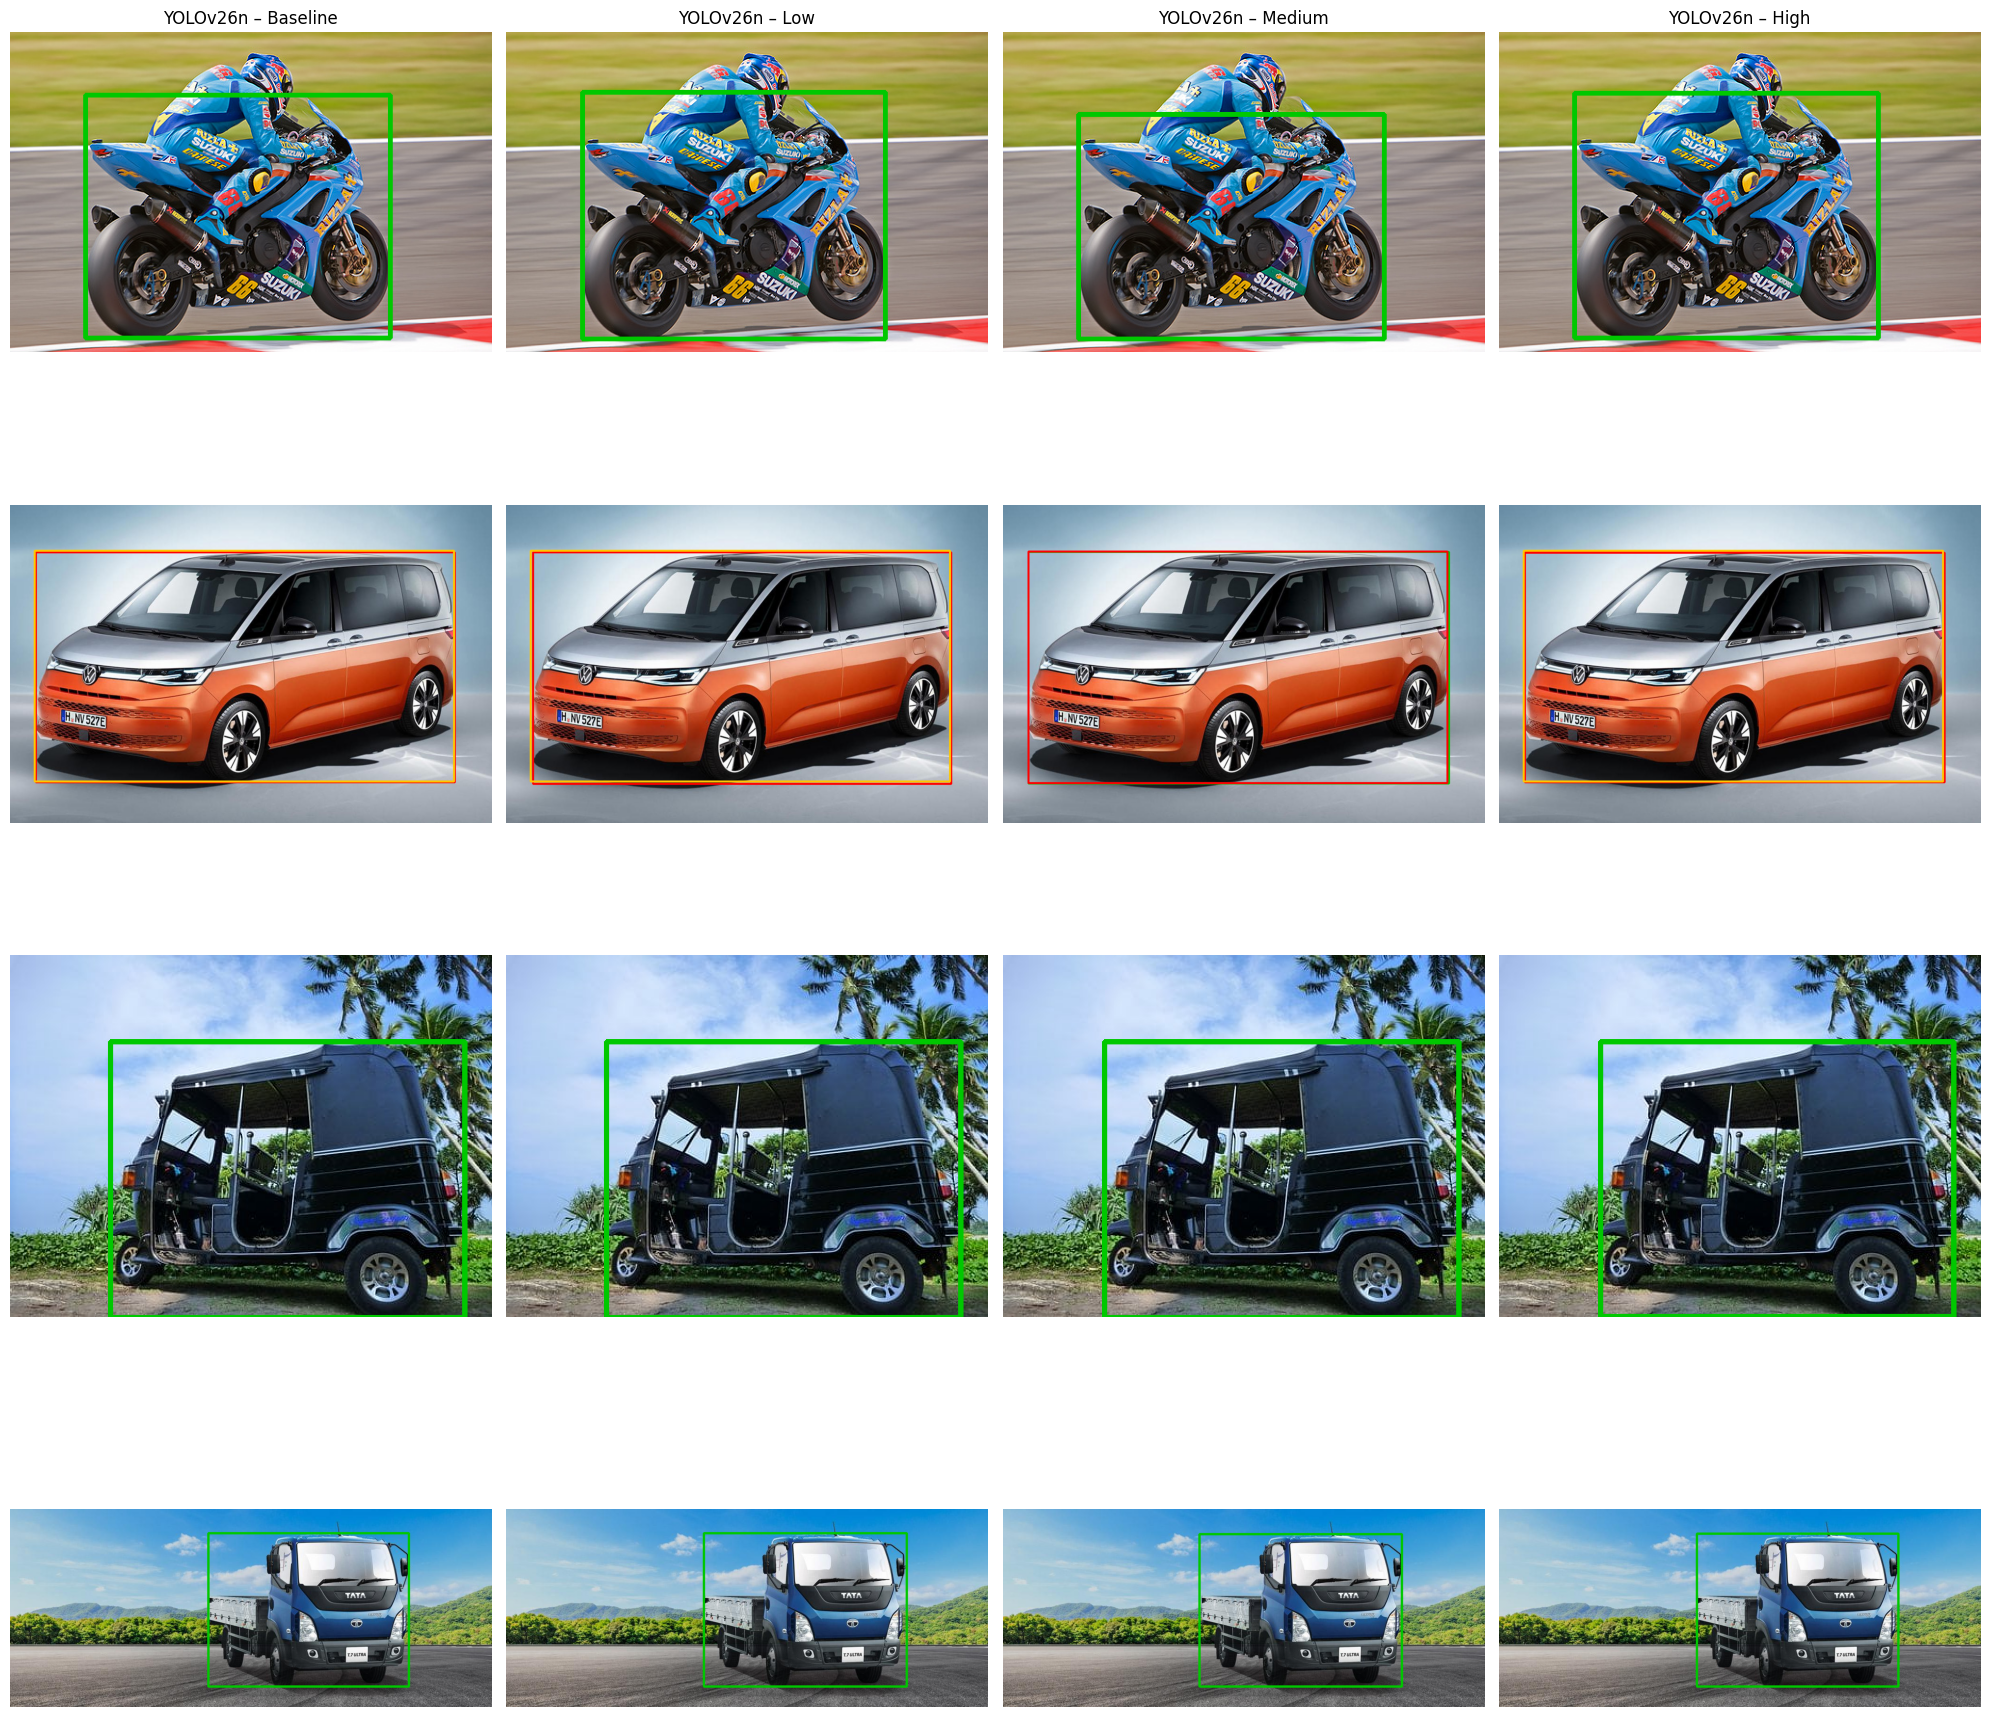

In [22]:
def draw(model, ip):
    img = cv2.cvtColor(cv2.imread(ip), cv2.COLOR_BGR2RGB)
    gts, tp, fp, fn = analyse(model, ip, lbl_of(ip))
    for b,c,s in tp: cv2.rectangle(img,(int(b[0]),int(b[1])),(int(b[2]),int(b[3])),(0,200,0),3)
    for b,c,s in fp: cv2.rectangle(img,(int(b[0]),int(b[1])),(int(b[2]),int(b[3])),(255,0,0),3)
    for g in fn:     cv2.rectangle(img,(int(g['box'][0]),int(g['box'][1])),(int(g['box'][2]),int(g['box'][3])),(255,200,0),3)
    return img

random.seed(1); picks = random.sample(imgs, 4)
for m in MODELS:
    fig, axes = plt.subplots(4, 4, figsize=(20,20))
    for j, lvl in enumerate(LEVELS):
        model = YOLO(weights[(lvl,m)])
        for i, ip in enumerate(picks):
            axes[i][j].imshow(draw(model, ip)); axes[i][j].axis('off')
            if i==0: axes[i][j].set_title(f'{m} – {lvl}')
    plt.tight_layout(); plt.savefig(f'samples_{m}.png', dpi=120); plt.show()

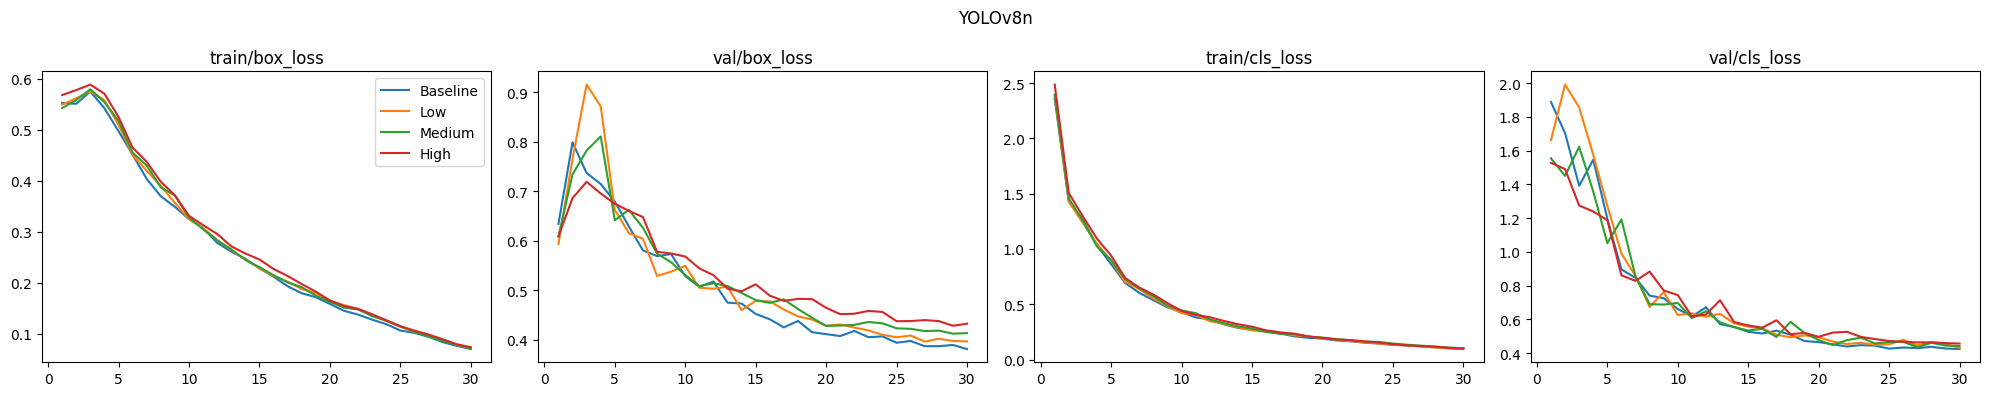

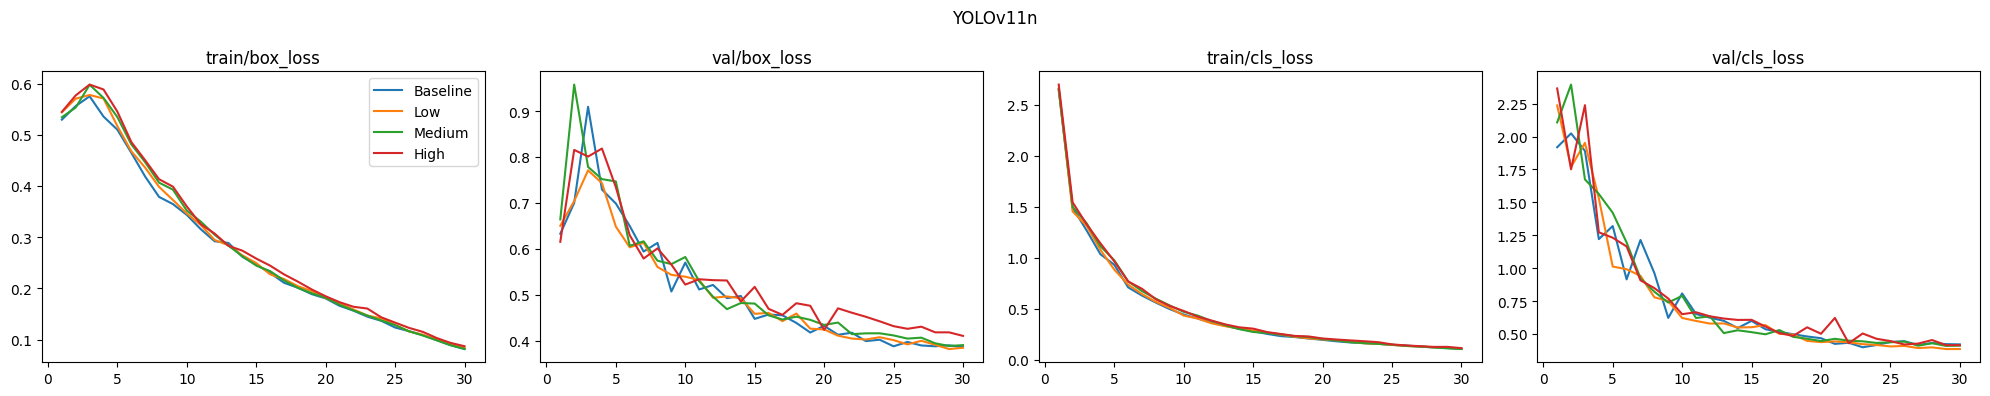

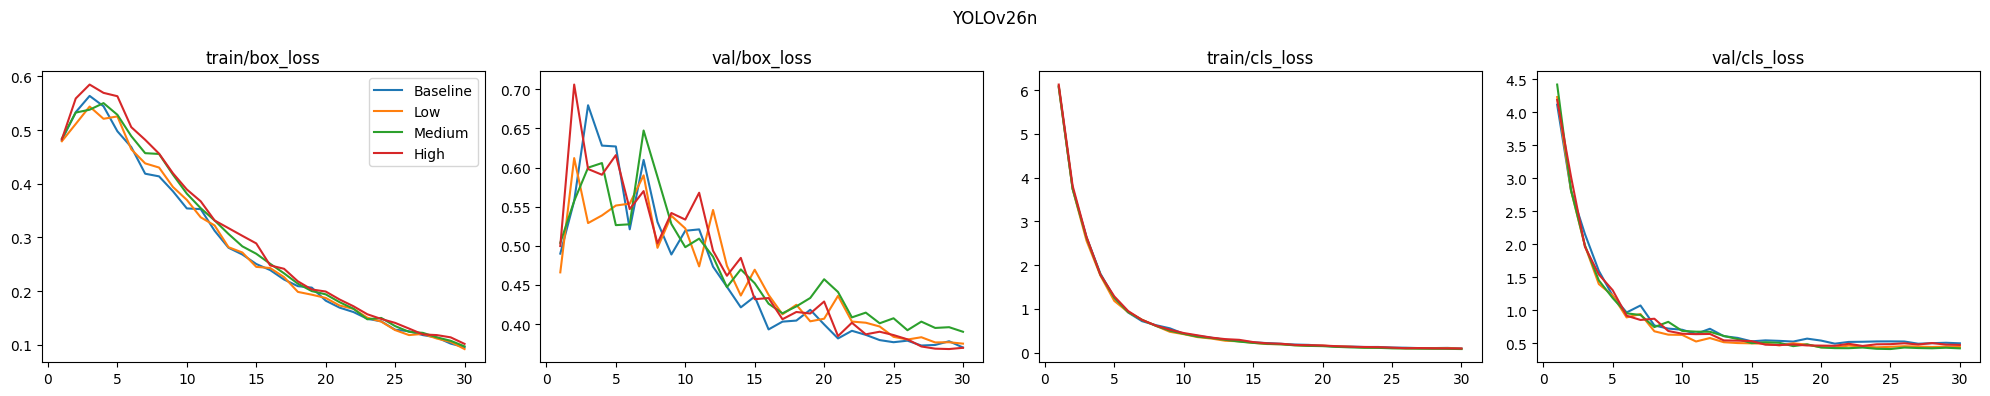

In [23]:
for m in MODELS:
    fig, axes = plt.subplots(1, 4, figsize=(20,4))
    for lvl in LEVELS:
        df = pd.read_csv(f'{folder(lvl,m)}/results.csv'); df.columns = df.columns.str.strip()
        for ax, col in zip(axes, ['train/box_loss','val/box_loss','train/cls_loss','val/cls_loss']):
            ax.plot(df['epoch'], df[col], label=lvl); ax.set_title(col)
    axes[0].legend(); fig.suptitle(m); plt.tight_layout(); plt.savefig(f'loss_{m}.png', dpi=150)

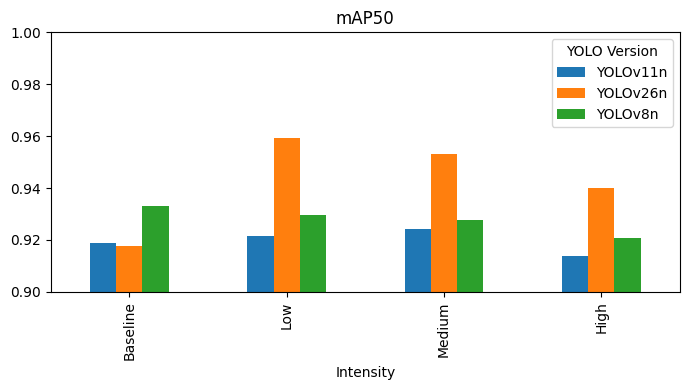

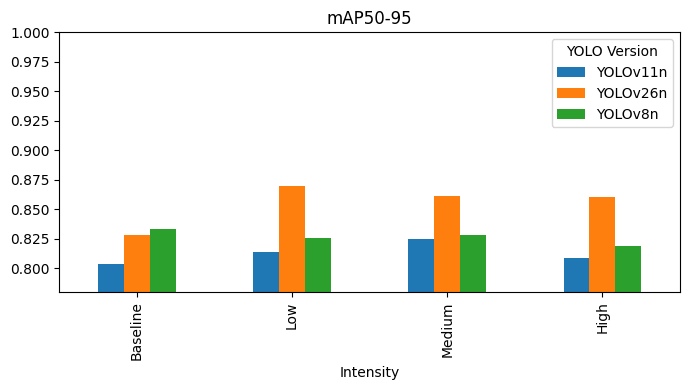

In [24]:
w3 = pd.read_csv('/content/week3_augmented_results.csv')
base = pd.DataFrame({'Intensity':'Baseline','YOLO Version':MODELS,
                     'mAP50':[0.9329,0.9189,0.9176],'mAP50-95':[0.8337,0.8038,0.8283]})
allr = pd.concat([base, w3[['Intensity','YOLO Version','mAP50','mAP50-95']]])
for metric in ['mAP50','mAP50-95']:
    t = allr.pivot(index='Intensity', columns='YOLO Version', values=metric).loc[LEVELS]
    t.plot(kind='bar', figsize=(7,4), ylim=(0.78 if metric=='mAP50-95' else 0.9, 1)); plt.title(metric); plt.tight_layout()
    plt.savefig(f'map_{metric}.png', dpi=150)

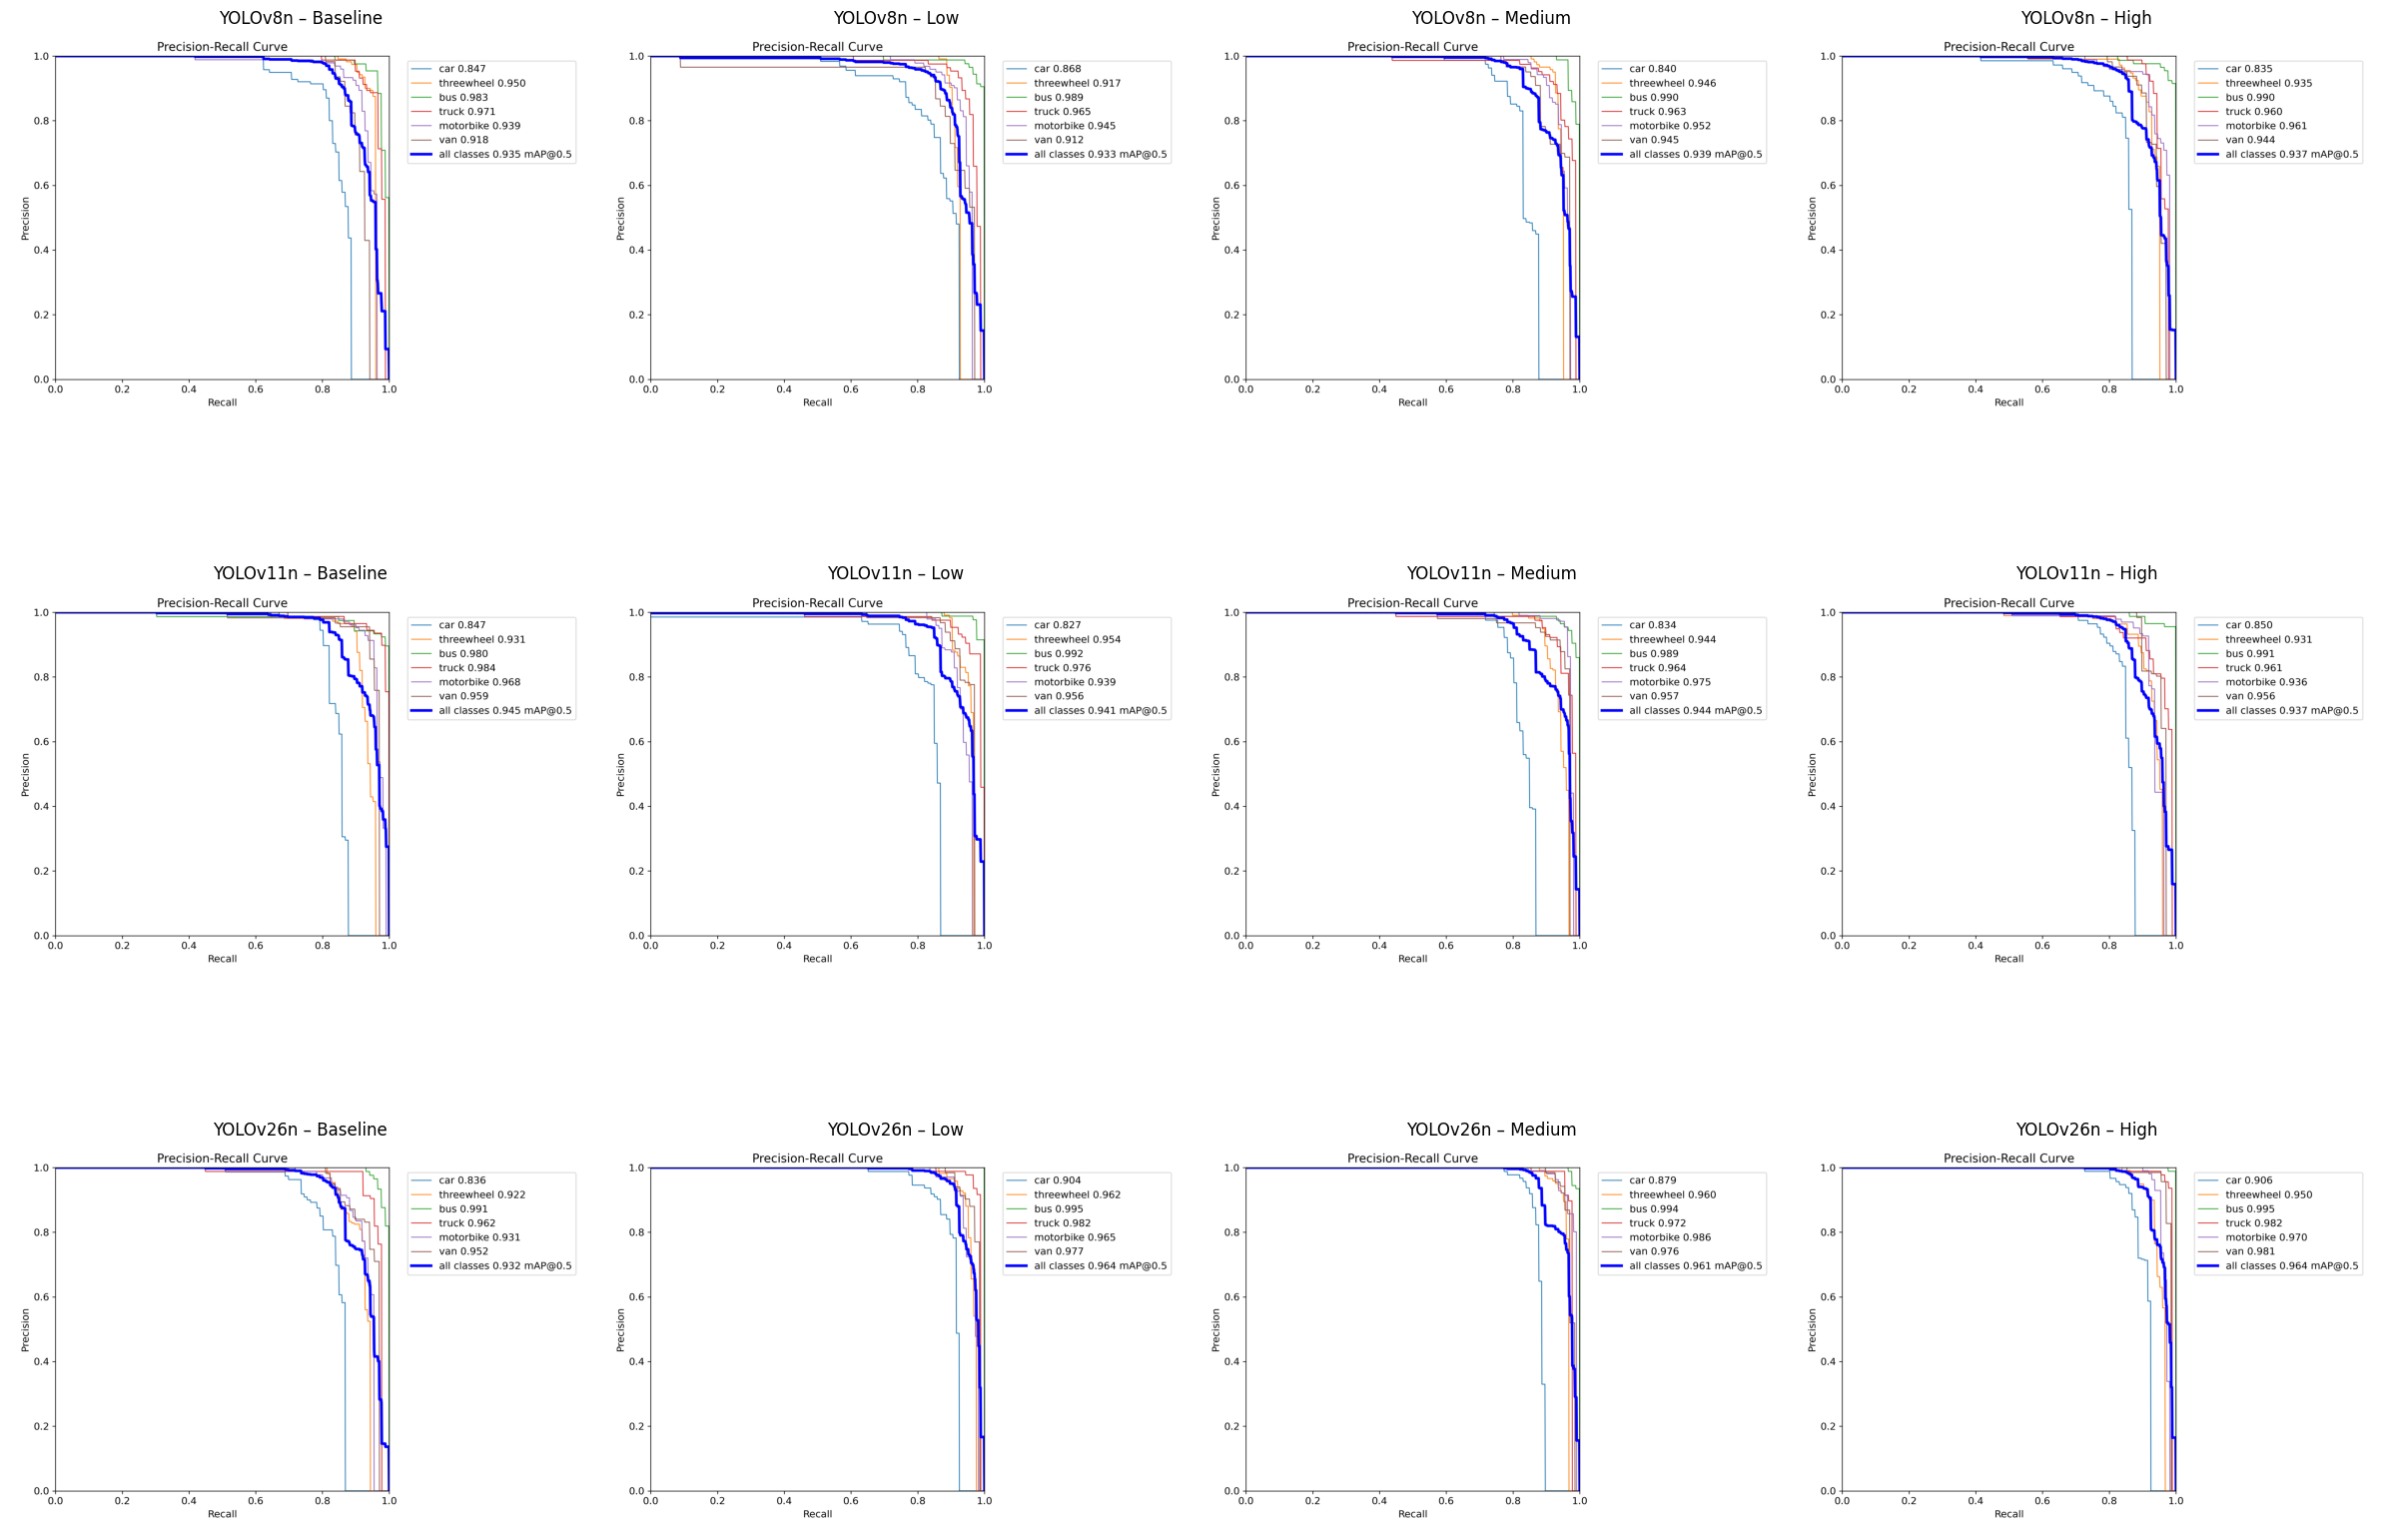

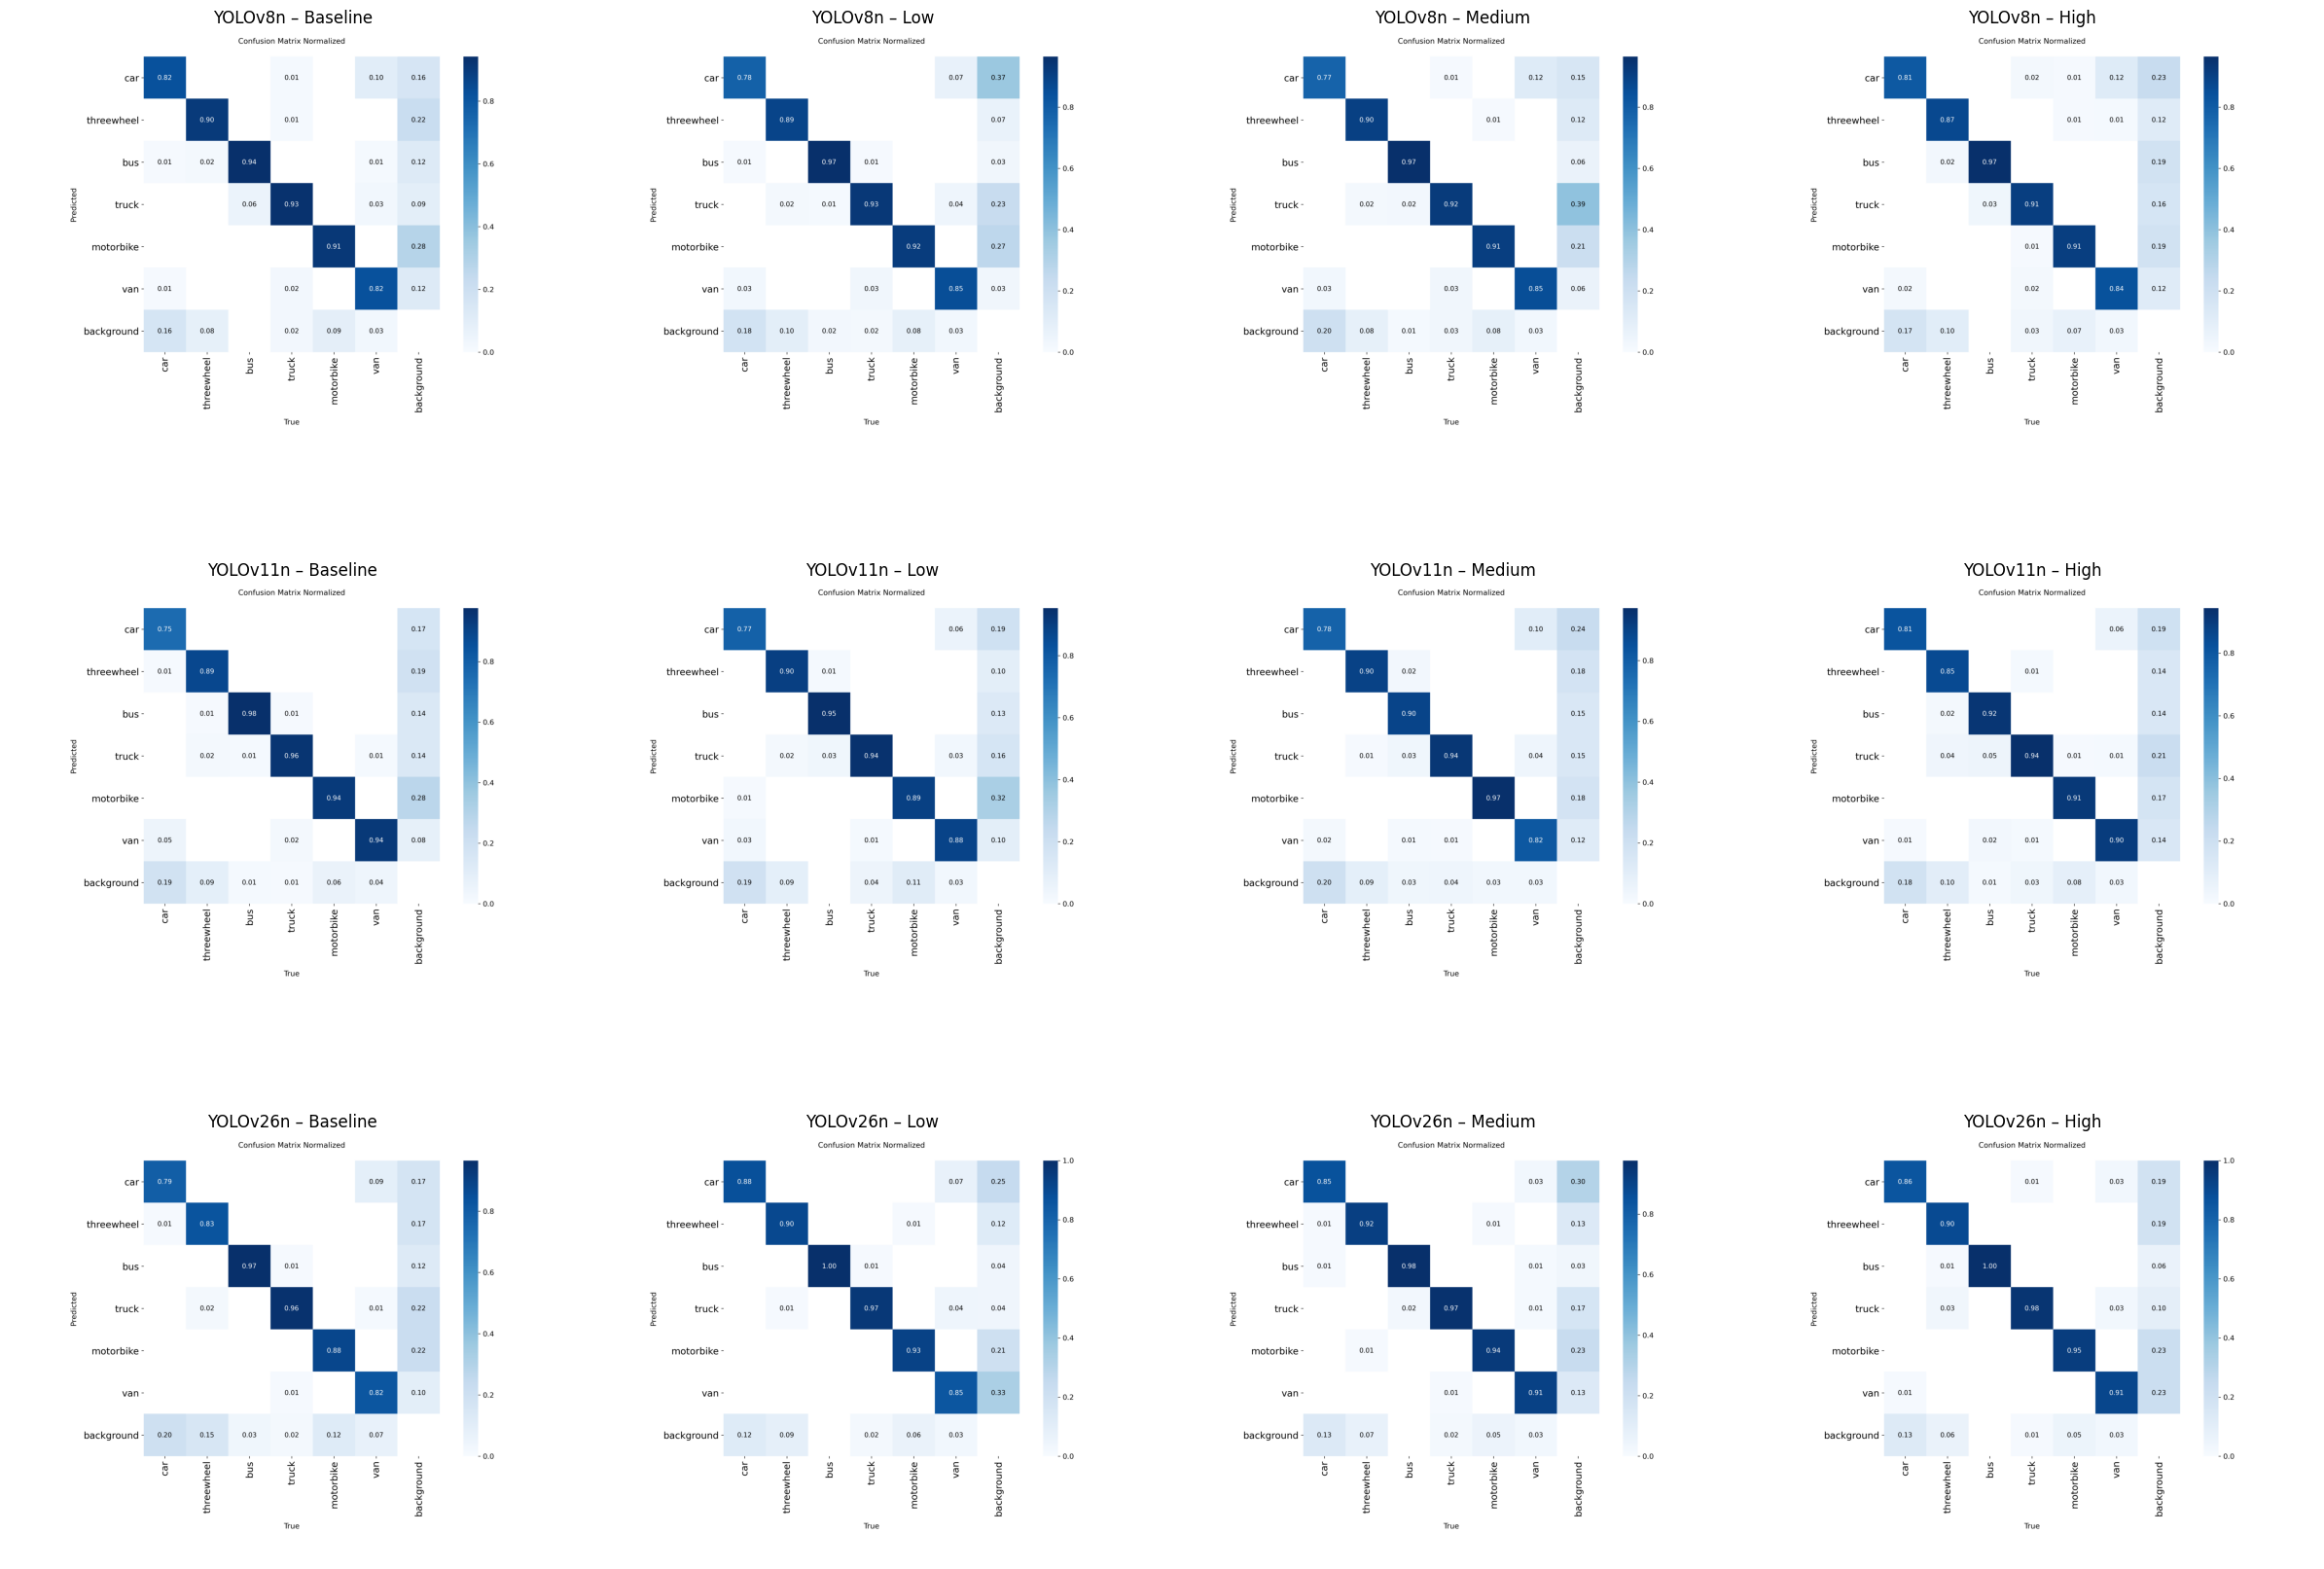

In [25]:
for name, fname in [('PR','BoxPR_curve.png'), ('confusion','confusion_matrix_normalized.png')]:
    fig, axes = plt.subplots(3, 4, figsize=(24,18))
    for i, m in enumerate(MODELS):
        for j, lvl in enumerate(LEVELS):
            axes[i][j].imshow(mpimg.imread(f'{folder(lvl,m)}/{fname}'))
            axes[i][j].set_title(f'{m} – {lvl}'); axes[i][j].axis('off')
    plt.tight_layout(); plt.savefig(f'{name}_grid.png', dpi=130)

In [26]:
!zip -q week5_outputs.zip *.png *.csv
from google.colab import files
files.download('week5_outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>